In [1]:
from pathlib import Path

import pandas as pd
from tqdm.auto import tqdm
from rdkit import Chem
from rdkit.Chem import PandasTools
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams

In [2]:
# load data from Talktorial T2
egfr_data = pd.read_csv("EGFR_compounds_lipinski.csv", index_col=0)
# Drop unnecessary information
print("Dataframe shape:", egfr_data.shape)
egfr_data.drop(columns=["molecular_weight", "n_hbd", "n_hba", "logp"], inplace=True)
egfr_data.head()

Dataframe shape: (101, 10)


,molecule_chembl_id,IC50,units,smiles,pIC50,ro5_fulfilled
0,CHEMBL304271,0.45,nM,CCN(CC)CC(O)CNC(=O)c1cc(C)c(/C=C2\C(=O)Nc3ncnc...,9.346787,True
1,CHEMBL264382,1.10,nM,Cc1cc(C(=O)NCCN2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncn...,8.958607,True
2,CHEMBL69358,1.20,nM,CCN(CC)CCNC(=O)c1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4...,8.920819,True
3,CHEMBL67003,1.80,nM,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,8.744727,True
4,CHEMBL305246,2.80,nM,Cc1cc(C(=O)N2CCN(C)CC2)[nH]c1/C=C1\C(=O)Nc2ncn...,8.552842,True


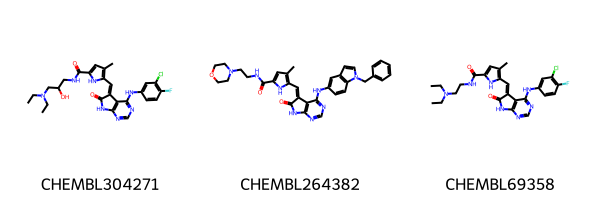

In [3]:
# Add molecule column
PandasTools.AddMoleculeColumnToFrame(egfr_data, smilesCol="smiles")
# Draw first 3 molecules
Chem.Draw.MolsToGridImage(
    list(egfr_data.head(3).ROMol),#add ROMol Column and list the first 3 drawings. 
    legends=list(egfr_data.head(3).molecule_chembl_id),#add the IDs as labels/legend.
)

In [4]:
# initialize filter
params = FilterCatalogParams()
params.AddCatalog(FilterCatalogParams.FilterCatalogs.PAINS)
catalog = FilterCatalog(params)

In [5]:
# search for PAINS
matches = []
clean = []
for index, row in tqdm(egfr_data.iterrows(), total=egfr_data.shape[0]): #go through every index/row 
    molecule = Chem.MolFromSmiles(row.smiles) #render it from words to structure
    entry = catalog.GetFirstMatch(molecule)  #search the catolog and get the first matching PAINS 
    if entry is not None:
        #store PAINS information
        matches.append(
            {
                "chembl_id": row.molecule_chembl_id,
                "rdkit_molecule": molecule,
                "pains": entry.GetDescription().capitalize(), #Go to entry where match is; get the description of PAINS. Capitalize each.
            }
        )
    else:
        #collect indices of molecules without PAINS
        clean.append(index)

matches = pd.DataFrame(matches) #puts all PAINS + molecules in one table
egfr_data = egfr_data.loc[clean]  #keep molecules without PAINS in another data set

  0%|          | 0/101 [00:00<?, ?it/s]

In [6]:
matches

,chembl_id,rdkit_molecule,pains
0,CHEMBL134312,<rdkit.Chem.rdchem.Mol object at 0x175e42500>,Azo_a(324)
1,CHEMBL136491,<rdkit.Chem.rdchem.Mol object at 0x175ebb290>,Azo_a(324)
2,CHEMBL133023,<rdkit.Chem.rdchem.Mol object at 0x175ebb370>,Azo_a(324)
3,CHEMBL424093,<rdkit.Chem.rdchem.Mol object at 0x175ebb3e0>,Azo_a(324)
4,CHEMBL137534,<rdkit.Chem.rdchem.Mol object at 0x175ebb450>,Azo_a(324)
5,CHEMBL137617,<rdkit.Chem.rdchem.Mol object at 0x175ebb4c0>,Azo_a(324)
6,CHEMBL137364,<rdkit.Chem.rdchem.Mol object at 0x175ebb300>,Azo_a(324)
7,CHEMBL136674,<rdkit.Chem.rdchem.Mol object at 0x175ebb5a0>,Azo_a(324)
8,CHEMBL133024,<rdkit.Chem.rdchem.Mol object at 0x175ebb530>,Azo_a(324)
9,CHEMBL137189,<rdkit.Chem.rdchem.Mol object at 0x175ebb680>,Azo_a(324)


In [7]:
egfr_data 

,molecule_chembl_id,IC50,units,smiles,pIC50,ro5_fulfilled,ROMol
0,CHEMBL304271,0.45,nM,CCN(CC)CC(O)CNC(=O)c1cc(C)c(/C=C2\C(=O)Nc3ncnc...,9.346787,True,<rdkit.Chem.rdchem.Mol object at 0x175e43d10>
1,CHEMBL264382,1.10,nM,Cc1cc(C(=O)NCCN2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncn...,8.958607,True,<rdkit.Chem.rdchem.Mol object at 0x175e43d80>
2,CHEMBL69358,1.20,nM,CCN(CC)CCNC(=O)c1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4...,8.920819,True,<rdkit.Chem.rdchem.Mol object at 0x175e43df0>
3,CHEMBL67003,1.80,nM,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,8.744727,True,<rdkit.Chem.rdchem.Mol object at 0x175e43e60>
4,CHEMBL305246,2.80,nM,Cc1cc(C(=O)N2CCN(C)CC2)[nH]c1/C=C1\C(=O)Nc2ncn...,8.552842,True,<rdkit.Chem.rdchem.Mol object at 0x175e43ed0>
5,CHEMBL67057,4.50,nM,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,8.346787,True,<rdkit.Chem.rdchem.Mol object at 0x175e43f40>
6,CHEMBL308645,4.70,nM,Cc1cc(CCC(=O)O)[nH]c1/C=C1\C(=O)Nc2ncnc(Nc3ccc...,8.327902,True,<rdkit.Chem.rdchem.Mol object at 0x175eb8040>
7,CHEMBL69071,5.90,nM,Cc1cc(C(=O)N2CC(C)NC(C)C2)[nH]c1/C=C1\C(=O)Nc2...,8.229148,True,<rdkit.Chem.rdchem.Mol object at 0x175eb80b0>
8,CHEMBL69629,6.50,nM,Cc1cc(C(=O)NCCN2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncn...,8.187087,True,<rdkit.Chem.rdchem.Mol object at 0x175eb8120>
10,CHEMBL66570,13.00,nM,CCN1CCN(C(=O)c2cc(C)c(/C=C3\C(=O)Nc4ncnc(Nc5cc...,7.886057,True,<rdkit.Chem.rdchem.Mol object at 0x175eb8200>


In [8]:
# NBVAL_CHECK_OUTPUT
print(f"Number of compounds with PAINS: {len(matches)}")
print(f"Number of compounds without PAINS: {len(egfr_data)}")

Number of compounds with PAINS: 48
Number of compounds without PAINS: 53


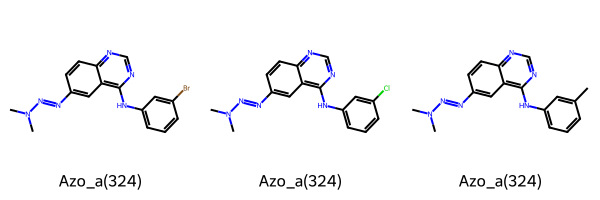

In [9]:
Chem.Draw.MolsToGridImage(
    list(matches.head(3).rdkit_molecule), #output the first 3 rdkit_molecule drawings from matches
    legends=list(matches.head(3)["pains"]), #put the PAINs label for each (legend)
)

In [10]:
from rdkit import Chem
import pandas as pd

# Load the CSV file
substructures = pd.read_csv("table_s1_unwanted_groups.csv")

# Use the exact column name from the CSV ('Smarts pattern')
substructures["Mol"] = substructures["Smarts pattern"].apply(Chem.MolFromSmarts)

print(
    "Number of unwanted substructures in collection:", len(substructures)
)  #[cite: 1]

Number of unwanted substructures in collection: 104


[19:02:21] SMARTS Parse Error: syntax error while parsing: nlc([F,Cl,Br,I])ccccl
[19:02:21] SMARTS Parse Error: check for mistakes around position 2:
[19:02:21] nlc([F,Cl,Br,I])ccccl
[19:02:21] ~^
[19:02:21] SMARTS Parse Error: Failed parsing SMARTS 'nlc([F,Cl,Br,I])ccccl' for input: 'nlc([F,Cl,Br,I])ccccl'
[19:02:21] SMARTS Parse Error: syntax error while parsing: [CX4][Cl,
[19:02:21] SMARTS Parse Error: check for mistakes around position 9:
[19:02:21] [CX4][Cl,
[19:02:21] ~~~~~~~~^
[19:02:21] SMARTS Parse Error: Failed parsing SMARTS '[CX4][Cl,' for input: '[CX4][Cl,'
[19:02:21] SMARTS Parse Error: syntax error while parsing: N=[N+]=[N-],
[19:02:21] SMARTS Parse Error: check for mistakes around position 12:
[19:02:21] N=[N+]=[N-],
[19:02:21] ~~~~~~~~~~~^
[19:02:21] SMARTS Parse Error: Failed parsing SMARTS 'N=[N+]=[N-],' for input: 'N=[N+]=[N-],'
[19:02:21] SMARTS Parse Error: syntax error while parsing: c~lc([OH])c([OH,NH2,NH])ccc~l
[19:02:21] SMARTS Parse Error: check for mistakes 

In [12]:
substructures.head()

,Name,Smarts pattern,Mol
0,2 ester groups,"C(=O)O[C,H1].C(=O)O[C,H1].C(=O)O[C,H1]",<rdkit.Chem.rdchem.Mol object at 0x175eba9d0>
1,2-halo pyridine,"nlc([F,Cl,Br,I])ccccl",None
2,acid halide,"C(=O)[Cl,Br,I,F]",<rdkit.Chem.rdchem.Mol object at 0x175ebab20>
3,acyclic C=C-O,C=[C!r]O,<rdkit.Chem.rdchem.Mol object at 0x175ebaab0>
4,acyl cyanide,N#CC(=O),<rdkit.Chem.rdchem.Mol object at 0x175ebab90>


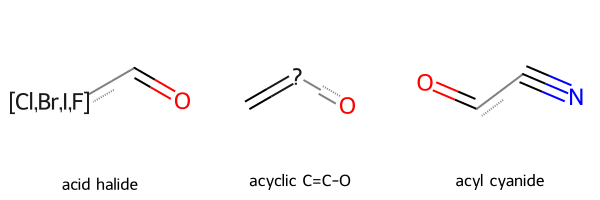

In [13]:
Chem.Draw.MolsToGridImage(
    mols = substructures.Mol.tolist()[2:5],
    legends = substructures.Name.tolist()[2:5],
)

In [46]:
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams
from tqdm import tqdm
import pandas as pd

# initialize filter
params = FilterCatalogParams()
params.AddCatalog(FilterCatalogParams.FilterCatalogs.PAINS)
catalog = FilterCatalog(params)

# search for PAINS
matches = []
clean = []

for index, row in tqdm(substructures.iterrows(), total = substructures.shape[0]):
  molecule = row["Mol"]

  # Safely skip if the cell is None, NaN, or not a valid RDKit Mol object
  if pd.isna(molecule) or not isinstance(molecule, Chem.Mol):
    clean.append(index)
    continue

  entry = catalog.GetFirstMatch(molecule)

  if entry is not None:
    matches.append({
        "chembl_id": row["Name"],  # Using bracket notation for safety
        "rdkit_molecule": molecule,
        "pains": entry.GetDescription().capitalize(),
    })
  else:
    clean.append(index)

matches = pd.DataFrame(matches)
substructures = substructures.loc[clean]

100%|██████████████████████████████████████| 104/104 [00:00<00:00, 8333.32it/s]


In [47]:
# NBVAL_CHECK_OUTPUT
print(f"Number of found unwanted substructure: {len(matches)}")
print(f"Number of compounds without unwanted substructure: {len(substructures)}")

Number of found unwanted substructure: 2
Number of compounds without unwanted substructure: 102


In [55]:
substructures

,Name,Smarts pattern,Mol
0,2 ester groups,"C(=O)O[C,H1].C(=O)O[C,H1].C(=O)O[C,H1]",<rdkit.Chem.rdchem.Mol object at 0x175eba9d0>
1,2-halo pyridine,"nlc([F,Cl,Br,I])ccccl",None
2,acid halide,"C(=O)[Cl,Br,I,F]",<rdkit.Chem.rdchem.Mol object at 0x175ebab20>
3,acyclic C=C-O,C=[C!r]O,<rdkit.Chem.rdchem.Mol object at 0x175ebaab0>
4,acyl cyanide,N#CC(=O),<rdkit.Chem.rdchem.Mol object at 0x175ebab90>
...,...,...,...
99,thiol (2),[SH],<rdkit.Chem.rdchem.Mol object at 0x175ef2b90>
100,Three-membered heterocycle,"*1[O,S,N]*1",<rdkit.Chem.rdchem.Mol object at 0x175ef2c00>
101,triflate,OS(=O)(=O)C(F)(F)F,<rdkit.Chem.rdchem.Mol object at 0x175ef2c70>
102,triphenyl methyl-silyl,"[SiR0,CR0](c1ccccc1)(c2ccccc2)(c3ccccc3)",<rdkit.Chem.rdchem.Mol object at 0x175ef2ce0>


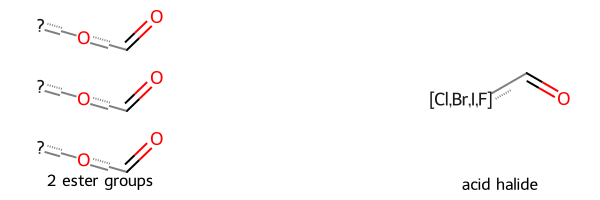

In [57]:
Chem.Draw.MolsToGridImage(
    list(substructures.head(3)["Mol"]),
    legends=list(substructures.head(3)["Name"]),
)

In [59]:
# NBVAL_CHECK_OUTPUT
groups = substructures.groupby("Name")
group_frequencies = groups.size()
group_frequencies.sort_values(ascending=False, inplace=True)
group_frequencies.head(10)

Name
2 ester groups              1
hydrazine                   1
nitro group                 1
methylidene-1,3-dithiole    1
ketene                      1
isolated alkene             1
isocyanate                  1
iodine                      1
imine (alt)                 1
imine                       1
dtype: int64